In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{\n  "username": "aahilyaiii",\n  "key": "KGAT_91f30951cb58332c589ebe93dd4e4b94"\n}'}

In [3]:
import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)

shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')

os.chmod('/root/.kaggle/kaggle.json', 600)

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [4]:
!kaggle datasets download -d joebeachcapital/customer-segmentation

Dataset URL: https://www.kaggle.com/datasets/joebeachcapital/customer-segmentation
License(s): DbCL-1.0
100% 1.55k/1.55k [00:00<00:00, 5.83MB/s]



In [5]:
import zipfile

zip_path = '/content/customer-segmentation.zip'

extract_path = '/content/customer_segmentation'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
import os

os.listdir('/content/customer_segmentation')

['Mall_Customers.csv']

In [7]:
import pandas as pd

df = pd.read_csv('/content/customer_segmentation/Mall_Customers.csv')

print("Dataset Loaded Successfully!")
df.head()
df.columns
df.info()
df.describe()
df.isnull().sum()


Dataset Loaded Successfully!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [8]:
df.duplicated().sum()
df[df.duplicated()]
df.drop_duplicates(inplace=True)
df.duplicated().sum

<bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
195    False
196    False
197    False
198    False
199    False
Length: 200, dtype: bool>

In [11]:
# Define the list of categorical columns from the dataframe
categorical_columns = df.select_dtypes(include=['object']).columns

for col in categorical_columns:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())


Unique values in Gender:
['Male' 'Female']


In [12]:
df.drop_duplicates(inplace=True)

print("Duplicate rows removed successfully!")

Duplicate rows removed successfully!


In [13]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_columns:
    df[col].fillna(df[col].median(), inplace=True)

print("Numerical missing values handled successfully!")

Numerical missing values handled successfully!


In [14]:
categorical_columns = df.select_dtypes(include=['object']).columns

for col in categorical_columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("Categorical missing values handled successfully!")

df.isnull().sum()

Categorical missing values handled successfully!


,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


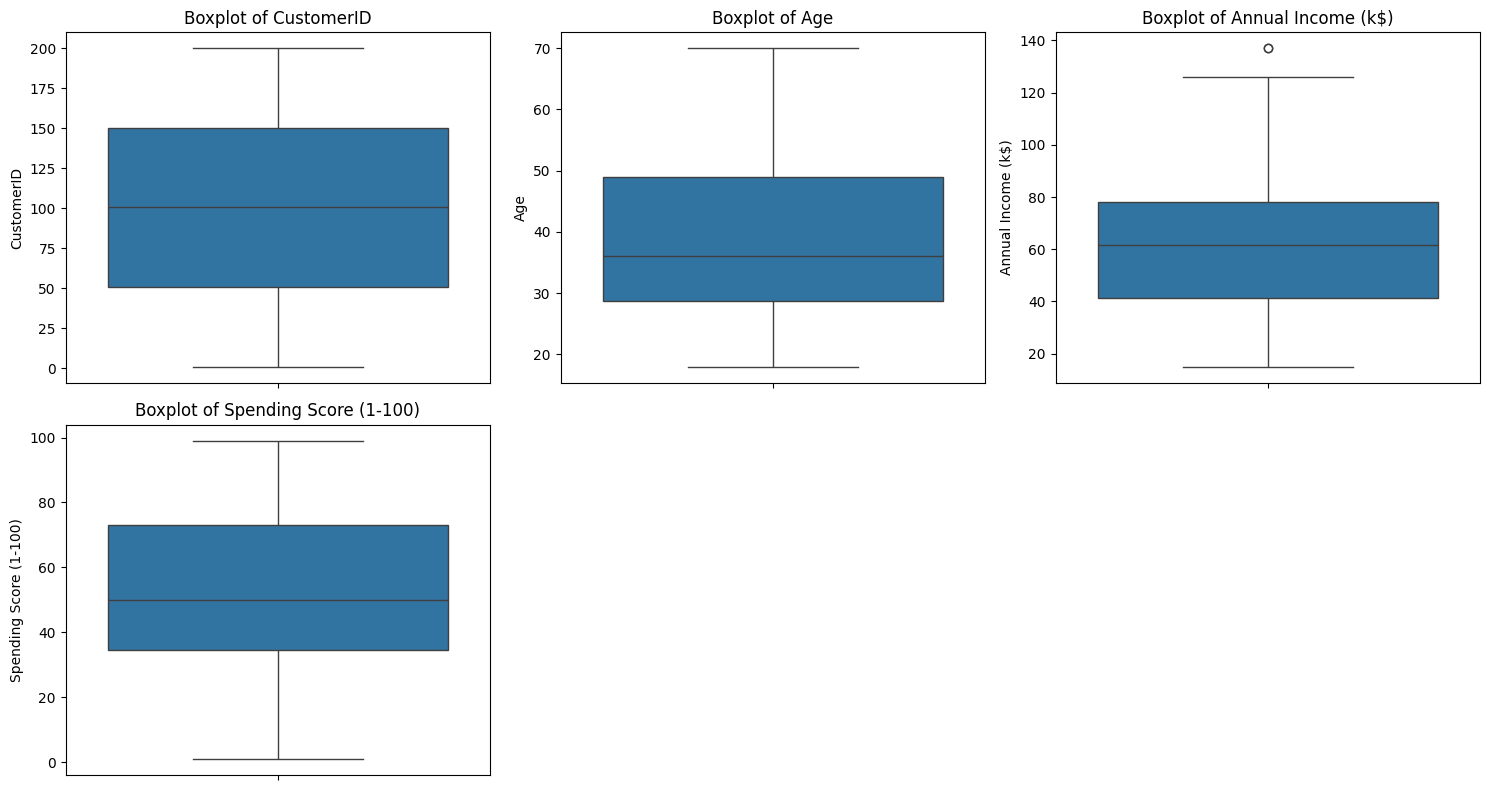

In [15]:
plt.figure(figsize=(15,8))

for i, col in enumerate(numerical_columns):

    plt.subplot(2,3,i+1)
    sns.boxplot(df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [ ]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"{col} : {len(outliers)} outliers")

In [16]:
# Label Encoding

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

for col in categorical_columns:
    df[col] = encoder.fit_transform(df[col])

print("Categorical features encoded successfully!")

Categorical features encoded successfully!


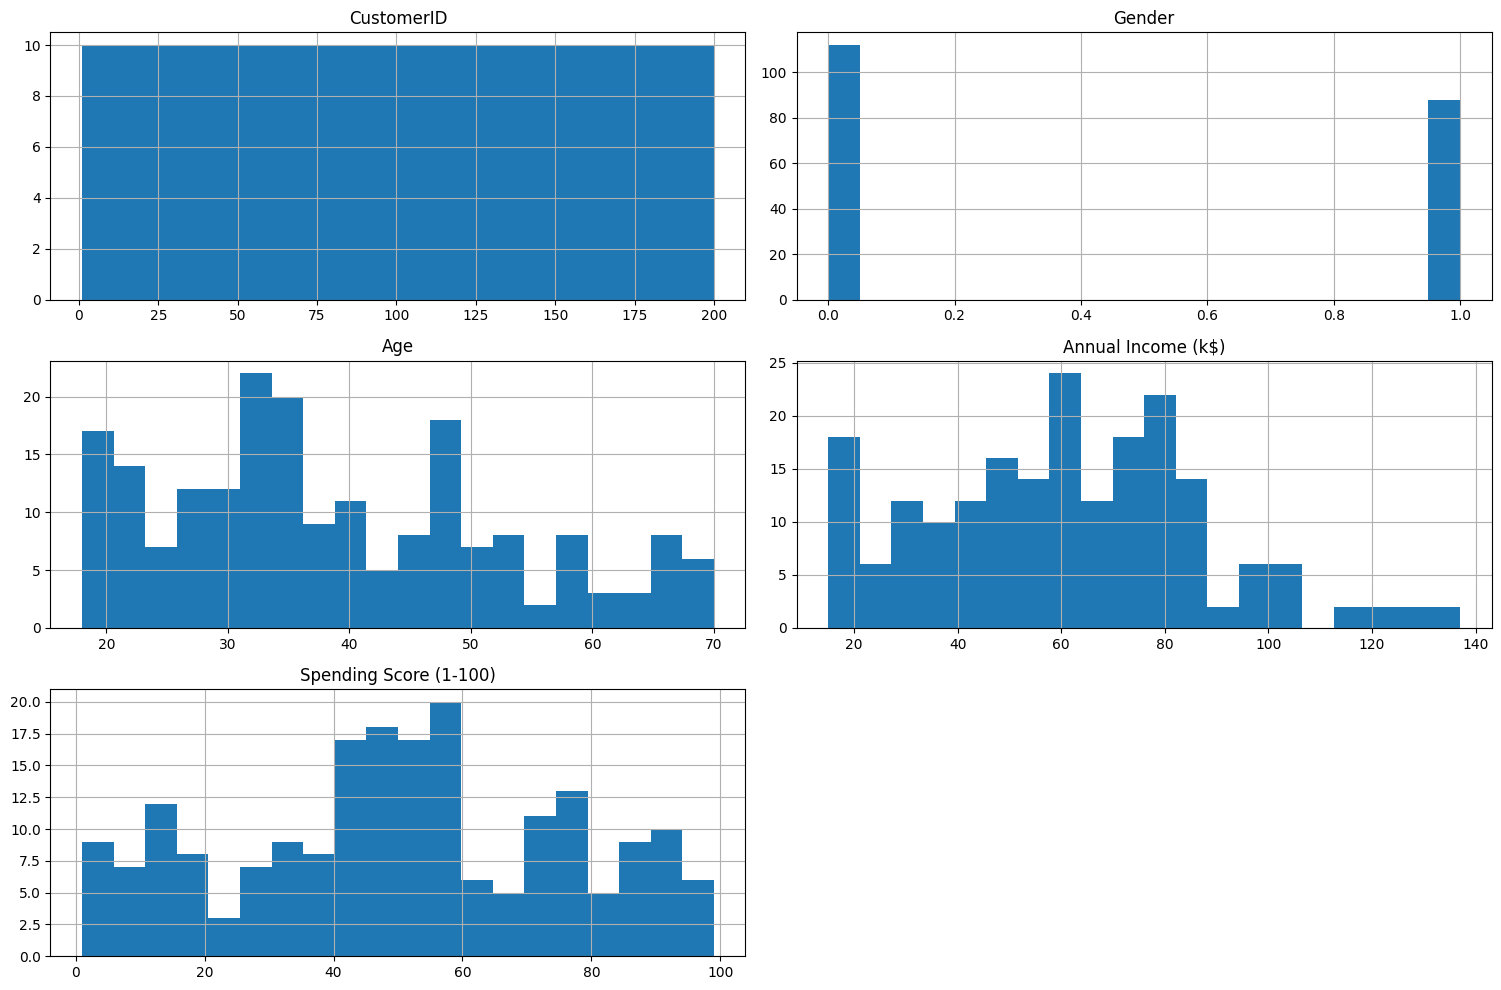

In [17]:

df.hist(figsize=(15,10), bins=20)

plt.tight_layout()
plt.show()

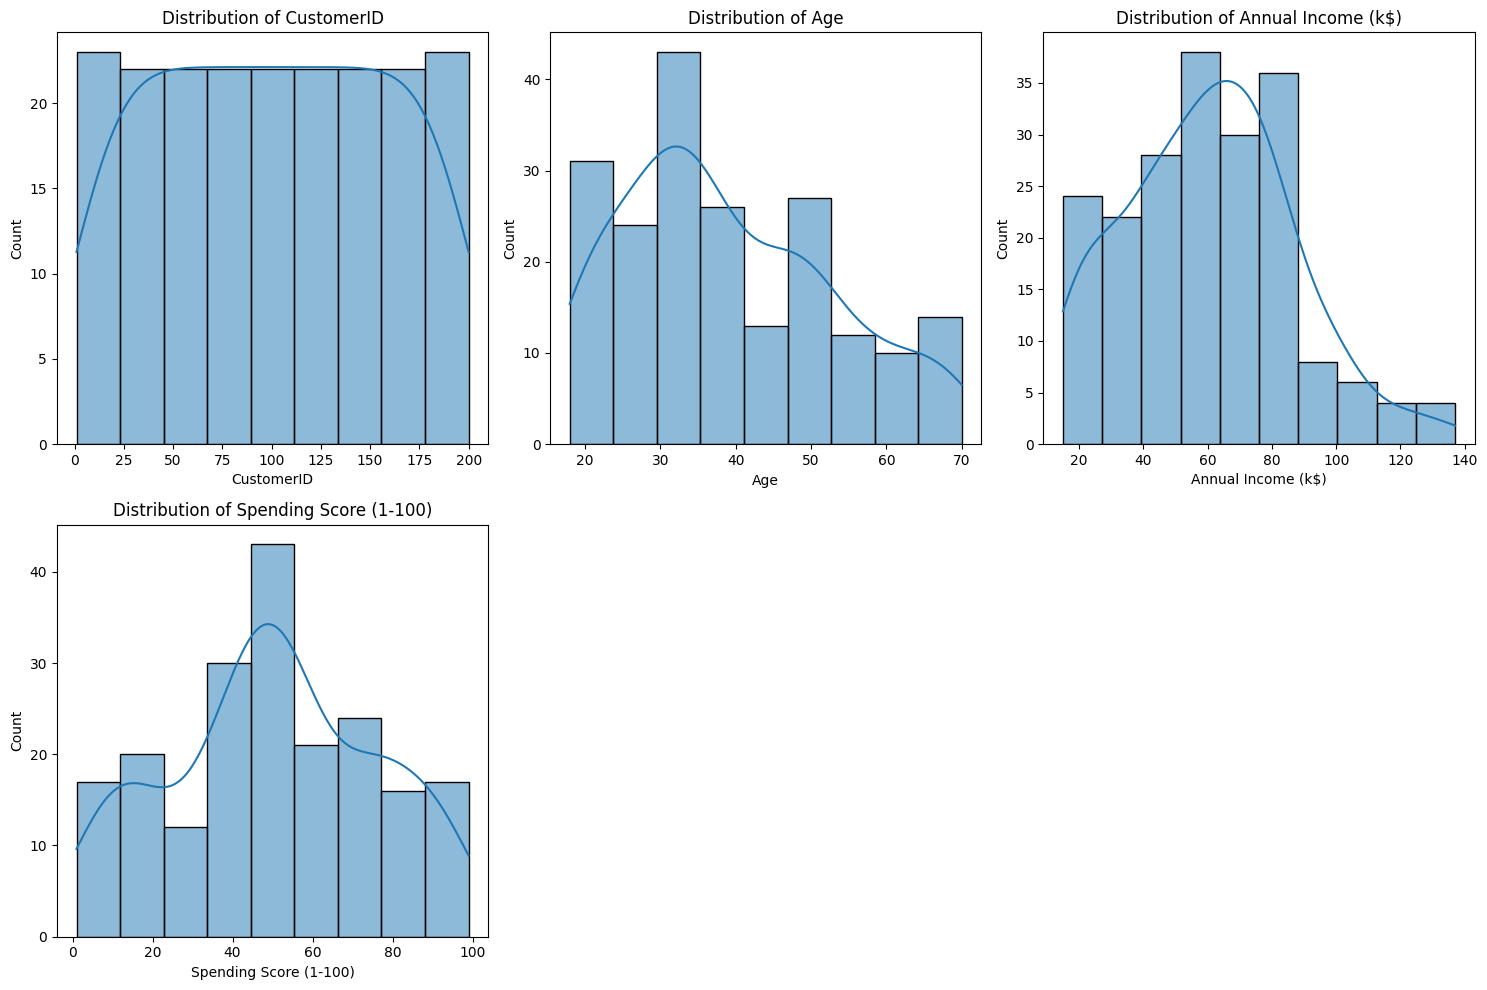

In [18]:
# Distribution Plots

plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_columns):

    plt.subplot(2,3,i+1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

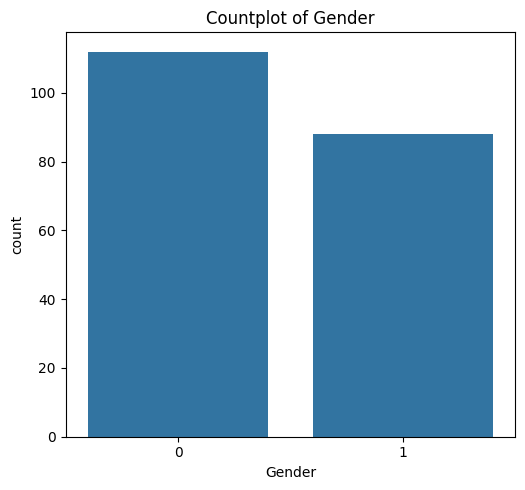

In [19]:
# Countplots for Categorical Features

plt.figure(figsize=(10,5))

for i, col in enumerate(categorical_columns):

    plt.subplot(1,2,i+1)
    sns.countplot(x=df[col])
    plt.title(f'Countplot of {col}')

plt.tight_layout()
plt.show()

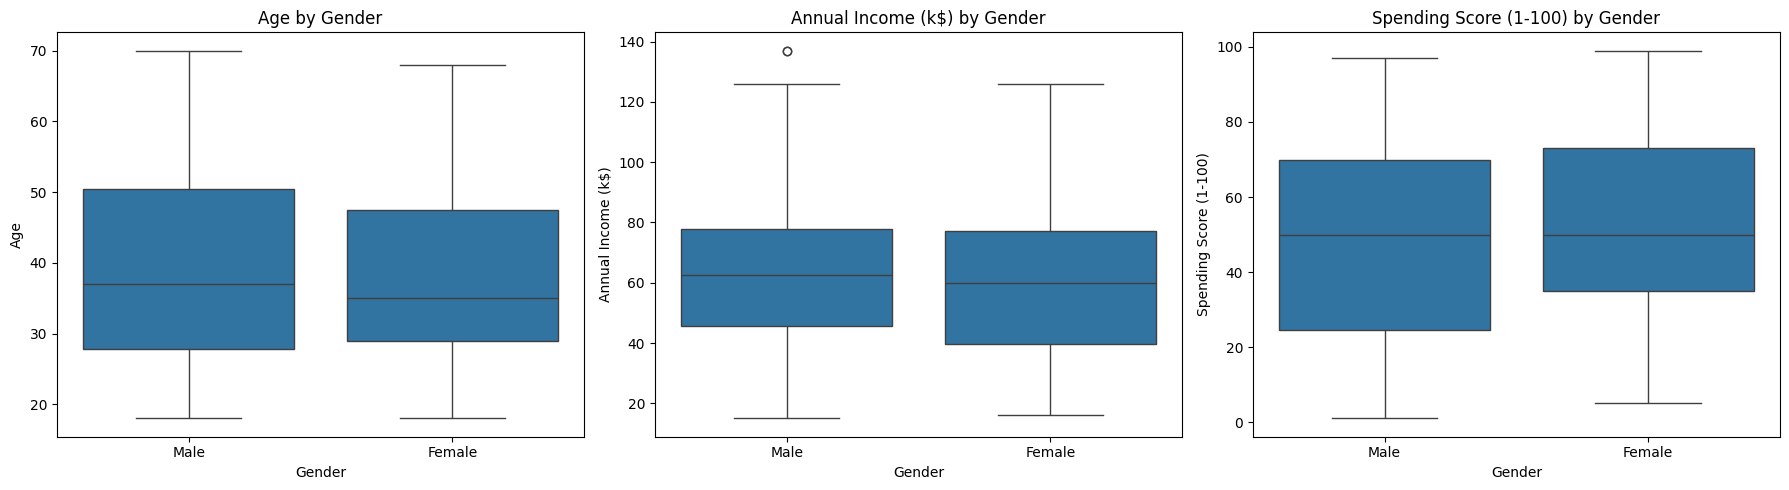

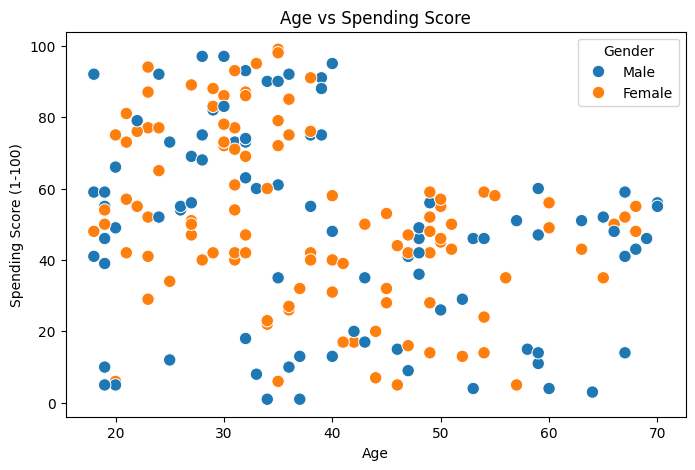

,Age,Annual Income (k$),Spending Score (1-100)
Gender,,,
Female,38.10,59.25,51.53
Male,39.81,62.23,48.51


In [20]:
eda_df = df.assign(Gender=df['Gender'].map({0: 'Female', 1: 'Male'}))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']):
    sns.boxplot(x='Gender', y=col, data=eda_df, ax=ax)
    ax.set_title(f'{col} by Gender')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=eda_df, x='Age', y='Spending Score (1-100)', hue='Gender', s=80)
plt.title('Age vs Spending Score')
plt.show()

eda_df.groupby('Gender')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(2)

In [21]:
cluster_features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[cluster_features]

scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

scaled_df = pd.DataFrame(scaled_data, columns=cluster_features)
scaled_df.describe().round(2)

,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.74,-1.91
25%,-0.73,-0.60
50%,0.04,-0.01
75%,0.67,0.89
max,2.92,1.89


In [22]:
optimal_k = 5

kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(scaled_data)

df['Cluster'] = cluster_labels

print("Silhouette Score:", round(silhouette_score(scaled_data, cluster_labels), 3))
df['Cluster'].value_counts().sort_index()

Silhouette Score: 0.555


,count
Cluster,
0,81
1,39
2,22
3,35
4,23


Explained variance ratio: [0.443 0.333]


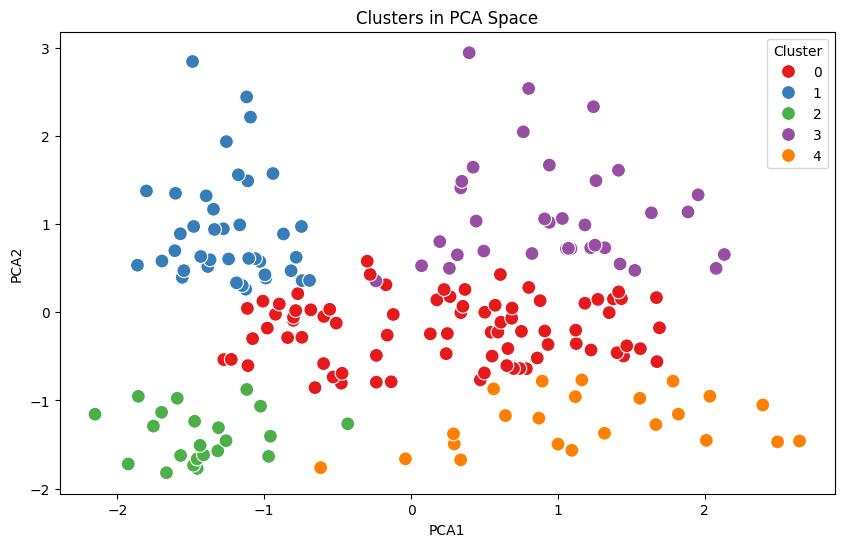

In [23]:
pca_features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
pca_input = StandardScaler().fit_transform(df[pca_features])

pca = PCA(n_components=2, random_state=42)
pca_data = pca.fit_transform(pca_input)

pca_df = pd.DataFrame(pca_data, columns=['PCA1', 'PCA2'])
pca_df['Cluster'] = df['Cluster'].values

print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(10, 6))
sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='Cluster', palette='Set1', s=100)
plt.title('Clusters in PCA Space')
plt.show()

In [24]:
profile = df.groupby('Cluster').agg(
    Customers=('Age', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income=('Annual Income (k$)', 'mean'),
    Avg_Spending=('Spending Score (1-100)', 'mean'),
    Male_Share=('Gender', 'mean')
).round(1)

inc_mean, inc_std = df['Annual Income (k$)'].mean(), df['Annual Income (k$)'].std()
spd_mean, spd_std = df['Spending Score (1-100)'].mean(), df['Spending Score (1-100)'].std()

def level(value, mean, std):
    if value >= mean + 0.5 * std:
        return 'High'
    if value <= mean - 0.5 * std:
        return 'Low'
    return 'Average'

profile['Segment'] = profile.apply(
    lambda r: f"{level(r['Avg_Income'], inc_mean, inc_std)} income / "
              f"{level(r['Avg_Spending'], spd_mean, spd_std)} spending",
    axis=1
)

df['Segment'] = df['Cluster'].map(profile['Segment'])
profile

,Customers,Avg_Age,Avg_Income,Avg_Spending,Male_Share,Segment
Cluster,,,,,,
0,81,42.7,55.3,49.5,0.4,Average income / Average spending
1,39,32.7,86.5,82.1,0.5,High income / High spending
2,22,25.3,25.7,79.4,0.4,Low income / High spending
3,35,41.1,88.2,17.1,0.5,High income / Low spending
4,23,45.2,26.3,20.9,0.4,Low income / Low spending


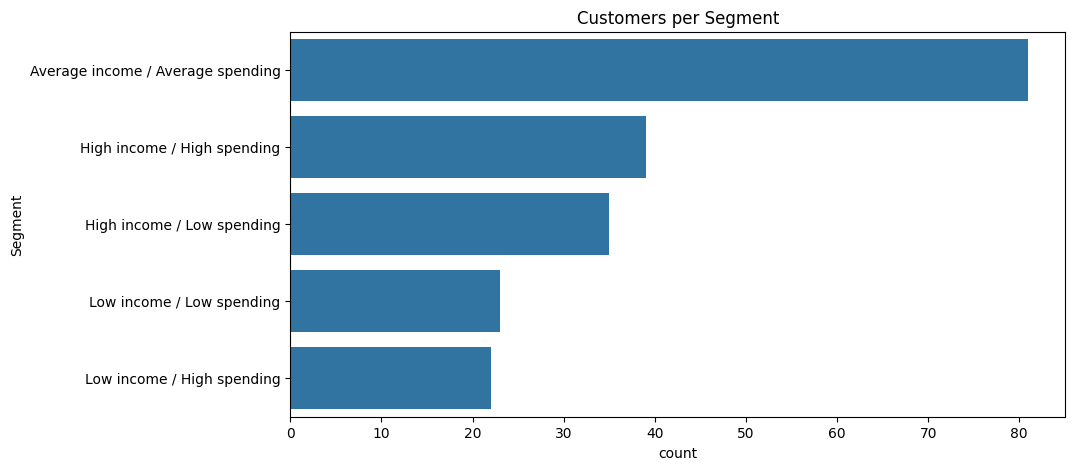

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
plt.figure(figsize=(10, 5))
sns.countplot(y=df['Segment'], order=df['Segment'].value_counts().index)
plt.title('Customers per Segment')
plt.show()

df.to_csv('customer_segments.csv', index=False)

from google.colab import files
files.download('customer_segments.csv')